## Ячейка 1: Загрузка Excel-файла

In [2]:
from google.colab import files

import getpass

import requests
import re
import time
import pandas as pd

import json
import os
import networkx as nx

import matplotlib.pyplot as plt

print("Выберите файл 'бсмо 12 айдишники вк.xlsx'")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f"Файл загружен: {filename}")

Выберите файл 'бсмо 12 айдишники вк.xlsx'


Saving бсмо 12 айдишники вк.xlsx to бсмо 12 айдишники вк.xlsx
Файл загружен: бсмо 12 айдишники вк.xlsx


In [16]:
# import getpass
VK_TOKEN = getpass.getpass("Enter your VK access token: ")
EXCEL_FILE = filename
DEPTH = 1 # 2 # 1 = только друзья, 2 = друзья друзей

print(f"Файл: {EXCEL_FILE}")
print(f"Токен: {VK_TOKEN[:15]}...")

Enter your VK access token: ··········
Файл: бсмо 12 айдишники вк.xlsx
Токен: f48ce0fef48ce0f...


## Ячейка 2: Сбор данных из VK

In [17]:
# import requests
# import re
# import time
# import pandas as pd

# this method does not reqiere the access_token. It's simply parsing the HTML link
def get_id_from_link(link):
    name = str(link).strip()
    name = re.sub(r'https?://', '', name)
    name = re.sub(r'(m\.)?vk\.(ru|com)/', '', name)
    name = name.strip('/').split('?')[0]

    if name.startswith('id') and name[2:].isdigit():
        return int(name[2:])

    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36',
        'Accept-Language': 'ru-RU,ru;q=0.9,en;q=0.8'
    }

    # Пробует разные домены
    for domain in ['vk.com', 'vk.ru', 'm.vk.com']:
        url = f"https://{domain}/{name}"
        try:
            r = requests.get(url, headers=headers, timeout=15, allow_redirects=True)

            # Способ А: /id12345678 в финальном URL
            match = re.search(r'/id(\d+)', r.url)
            if match:
                return int(match.group(1))

            # Способ Б: user_id в HTML
            match = re.search(r'"user_id":(\d+)', r.text)
            if match:
                return int(match.group(1))

            # Способ В: og:url с id
            match = re.search(r'og:url"\s+content="[^"]*?/id(\d+)', r.text)
            if match:
                return int(match.group(1))

            # Способ Г: ссылка на профиль в HTML
            match = re.search(r'vk\.com/id(\d+)', r.text)
            if match:
                return int(match.group(1))

        except Exception as e:
            print(f"Ошибка на {domain}: {e}")
            continue

    return None


# --- Основной процесс ---
print("Чтение Excel...")
df = pd.read_excel(EXCEL_FILE, header=None)
links = df[0].dropna().tolist()
print(f"Найдено ссылок: {len(links)}\n")

print("Получение ID без токена...")
group_members = []
failed_links = []

for i, link in enumerate(links, 1):
    print(f"[{i}/{len(links)}] {link}")
    uid = get_id_from_link(link)
    if uid:
        group_members.append(uid)
        print(f"ID: {uid}")
    else:
        failed_links.append(link)
        print(f"Не удалось. Проверьте вручную в браузере.")
    time.sleep(1)

print(f"\n{'='*60}")
print(f"Успешно получено ID: {len(group_members)}/{len(links)}")
print(f"Неудачных: {len(failed_links)}")
print(f"{'='*60}")

if failed_links:
    print("\nЭти ссылки не удалось распознать:")
    for fl in failed_links:
        print(f"   - {fl}")
    print("\nОткройте их вручную в браузере, скопируйте /idXXXXXXX из адресной строки")
    print("и добавьте в группу ниже вручную.\n")

# MANUAL_IDS = [
# ]
# group_members.extend(MANUAL_IDS)
group_members = list(set(group_members))

print(f"\nИтоговый список участников ({len(group_members)}):")
print(group_members)

# Save
with open("group_members.txt", "w") as f:
    f.write("\n".join(map(str, group_members)))
print("\nСохранено в group_members.txt")

Чтение Excel...
Найдено ссылок: 16

Получение ID без токена...
[1/16] https://vk.ru/andrew.kirillov
ID: 357111839
[2/16] https://m.vk.ru/bignigga
ID: 447383697
[3/16] https://vk.ru/y.doyneko
ID: 365680993
[4/16] https://vk.ru/saulinivan
ID: 223966628
[5/16] https://vk.ru/dimitr101
ID: 299547783
[6/16] https://vk.ru/ku_ku_riz
ID: 288851914
[7/16] https://vk.ru/medvediano
ID: 465105120
[8/16] https://vk.ru/flashik12
ID: 198182178
[9/16] https://vk.ru/0pupok00
ID: 473310225
[10/16] https://vk.ru/ryosuk3
ID: 424935969
[11/16] https://vk.ru/id139159408
ID: 139159408
[12/16] https://vk.ru/dedvnutree
ID: 236434667
[13/16] https://vk.ru/votkakblat
ID: 270876280
[14/16] https://vk.ru/sh3rryy
ID: 397017302
[15/16] https://vk.ru/asstynj
ID: 143873880
[16/16] https://vk.ru/foreverlostintears
ID: 322111274

Успешно получено ID: 16/16
Неудачных: 0

Итоговый список участников (16):
[465105120, 365680993, 198182178, 424935969, 223966628, 299547783, 288851914, 236434667, 322111274, 139159408, 447383697

In [18]:
# import json
# import os
# import requests
# import time
# import networkx as nx

CACHE_PATH = "friends_cache.json"
cache = json.load(open(CACHE_PATH)) if os.path.exists(CACHE_PATH) else {}

# def get_friends(user_id, token):
#     """Получает список друзей через VK API. Требует токен."""
#     params = {
#         'user_id': user_id,
#         'access_token': token,
#         'v': '5.131'
#     }
#     try:
#         r = requests.get('https://api.vk.com/method/friends.get', params=params, timeout=15).json()
#         if 'response' in r:
#             return r['response']['items']
#         elif 'error' in r:
#             err = r['error']
#             if err['error_code'] == 14:  # Captcha
#                 print(f"ERROR: Капча (или ограничение трафика)! Подождите 15-30 минут.")
#             else:
#                 print(f"ERROR: VK: {err['error_msg']}")
#             return []
#     except Exception as e:
#         print(f"ERROR: Ошибка сети: {e}")
#         return []
#     return []

def get_friends(uid, token):
    if str(uid) in cache:
        return cache[str(uid)]
    for attempt in range(3):
        r = requests.get("https://api.vk.com/method/friends.get", params={
            "user_id": uid, "access_token": token, "v": "5.131"
        }, timeout=15).json()
        if "response" in r:
            items = r["response"].get("items", [])
            cache[str(uid)] = items
            json.dump(cache, open(CACHE_PATH, "w"))
            return items
        code = r.get("error", {}).get("error_code")
        if code == 6:  time.sleep(10);  continue
        if code == 29: time.sleep(60);  continue
        if code in (15, 18, 30): return []
        print(f"VK error {code}: {r['error'].get('error_msg')}")
        return []
    return []

# Строим граф
print("Сбор друзей...\n")
G = nx.Graph()
G.add_nodes_from(group_members)

# for i, member in enumerate(group_members, 1):
#     print(f"[{i}/{len(group_members)}] Обработка {member}...")
#     friends = get_friends(member, VK_TOKEN)
#     print(f"   Друзей: {len(friends)}")
#
#     for friend in friends:
#         G.add_edge(member, friend)
#         # Глубина 2: если друг — тоже участник группы, связываем
#         if DEPTH >= 2 and friend in group_members:
#             G.add_edge(member, friend)
#
#     time.sleep(1)  # 1 секунда — против капчи/лимита трафика

# Phase 1 — friends
# level1 = {}
# for member in group_members:
#     fs = get_friends(member, VK_TOKEN)
#     level1[member] = fs
#     for f in fs:
#         G.add_edge(member, f)
for i, m in enumerate(group_members, 1):
    fs = get_friends(m, VK_TOKEN)
    print(f"[1-hop {i}/{len(group_members)}] {m} -> {len(fs)} friends")
    for f in fs:
        G.add_edge(m, f)
    # time.sleep(0.4)

# Phase 2 — friends of friends
# all_level1 = {f for fs in level1.values() for f in fs}
# for i, f in enumerate(all_level1, 1):
#     if f in level1:           # if already fetched
#         continue
#     ff = get_friends(f, VK_TOKEN)
#     level1[f] = ff            # cache — avoids duplicate API calls
#     for x in ff:
#         G.add_edge(f, x)
if DEPTH >= 2:
    level1 = {f for m in group_members for f in get_friends(m, VK_TOKEN)}
    for i, f in enumerate(level1, 1):
        ff = get_friends(f, VK_TOKEN)
        if i % 50 == 0:
            # Shows general progress
            print(f"[2-hop {i}/{len(level1)}] nodes={G.number_of_nodes()}")
        for x in ff:
          # if x not in G:
            G.add_edge(f, x)
        # time.sleep(0.35)

nx.write_gexf(G, "vk_graph.gexf")
print(f"\n Узлов: {G.number_of_nodes()}, Рёбер: {G.number_of_edges()}")

Сбор друзей...

[1-hop 1/16] 465105120 -> 181 friends
[1-hop 2/16] 365680993 -> 0 friends
[1-hop 3/16] 198182178 -> 0 friends
[1-hop 4/16] 424935969 -> 30 friends
[1-hop 5/16] 223966628 -> 153 friends
[1-hop 6/16] 299547783 -> 0 friends
[1-hop 7/16] 288851914 -> 105 friends
[1-hop 8/16] 236434667 -> 0 friends
[1-hop 9/16] 322111274 -> 157 friends
[1-hop 10/16] 139159408 -> 275 friends
[1-hop 11/16] 447383697 -> 104 friends
[1-hop 12/16] 473310225 -> 177 friends
[1-hop 13/16] 143873880 -> 0 friends
[1-hop 14/16] 397017302 -> 0 friends
[1-hop 15/16] 270876280 -> 0 friends
[1-hop 16/16] 357111839 -> 256 friends

 Узлов: 1350, Рёбер: 1436


## Ячейка 3: Расчёт центральностей

In [20]:
# import networkx as nx
# import pandas as pd

print("Анализ центральности...\n")

with open("group_members.txt", "r") as f:
    group_members = [int(line.strip()) for line in f.readlines() if line.strip()]

degree_cent = nx.degree_centrality(G)
closeness_cent = nx.closeness_centrality(G)
betweenness_cent = nx.betweenness_centrality(G, k=min(100, len(G)))

try:
    eigenvector_cent = nx.eigenvector_centrality(G, max_iter=1000)
except Exception as e:
    print(f"Eigenvector: {e}")
    eigenvector_cent = {node: 0 for node in G.nodes()}

# Собирает таблицу (только для членов группы, как требует задание)
data = []
for node in G.nodes():
    if node not in group_members:
        continue
    data.append({
        'User ID': node,
        'Degree': round(degree_cent.get(node, 0), 4),
        'Closeness': round(closeness_cent.get(node, 0), 4),
        'Betweenness': round(betweenness_cent.get(node, 0), 4),
        'Eigenvector': round(eigenvector_cent.get(node, 0), 4),
    })
    if i % 50 == 0:
      print(f"[Gone through: {i}/{len(level1)}] nodes")

df_result = pd.DataFrame(data)
df_result = df_result.sort_values(by='Degree', ascending=False).reset_index(drop=True)

print("=" * 80)
print("РЕЗУЛЬТАТЫ АНАЛИЗА ЦЕНТРАЛЬНОСТИ (только члены группы)")
print("=" * 80)
print(df_result.to_string(index=False))

df_result.to_csv("centrality_results.csv", index=False)
print("\nСохранено в centrality_results.csv")

Анализ центральности...

РЕЗУЛЬТАТЫ АНАЛИЗА ЦЕНТРАЛЬНОСТИ (только члены группы)
  User ID  Degree  Closeness  Betweenness  Eigenvector
139159408  0.2039     0.2077       0.2968       0.7042
357111839  0.1898     0.2915       0.5478       0.0046
465105120  0.1342     0.2299       0.2314       0.0009
473310225  0.1312     0.2298       0.1880       0.0009
322111274  0.1164     0.2704       0.5018       0.0480
223966628  0.1134     0.2319       0.1679       0.0428
288851914  0.0778     0.0778       0.0069       0.0000
447383697  0.0771     0.2151       0.1285       0.0000
424935969  0.0222     0.1587       0.0536       0.0000
299547783  0.0015     0.2136       0.0000       0.0055
365680993  0.0015     0.2136       0.0000       0.0055
198182178  0.0015     0.1881       0.0000       0.0001
270876280  0.0007     0.1744       0.0000       0.0000
397017302  0.0007     0.1744       0.0000       0.0000
236434667  0.0000     0.0000       0.0000       0.0000
143873880  0.0000     0.0000       0.000

## Ячейка 4: Визуализация графа

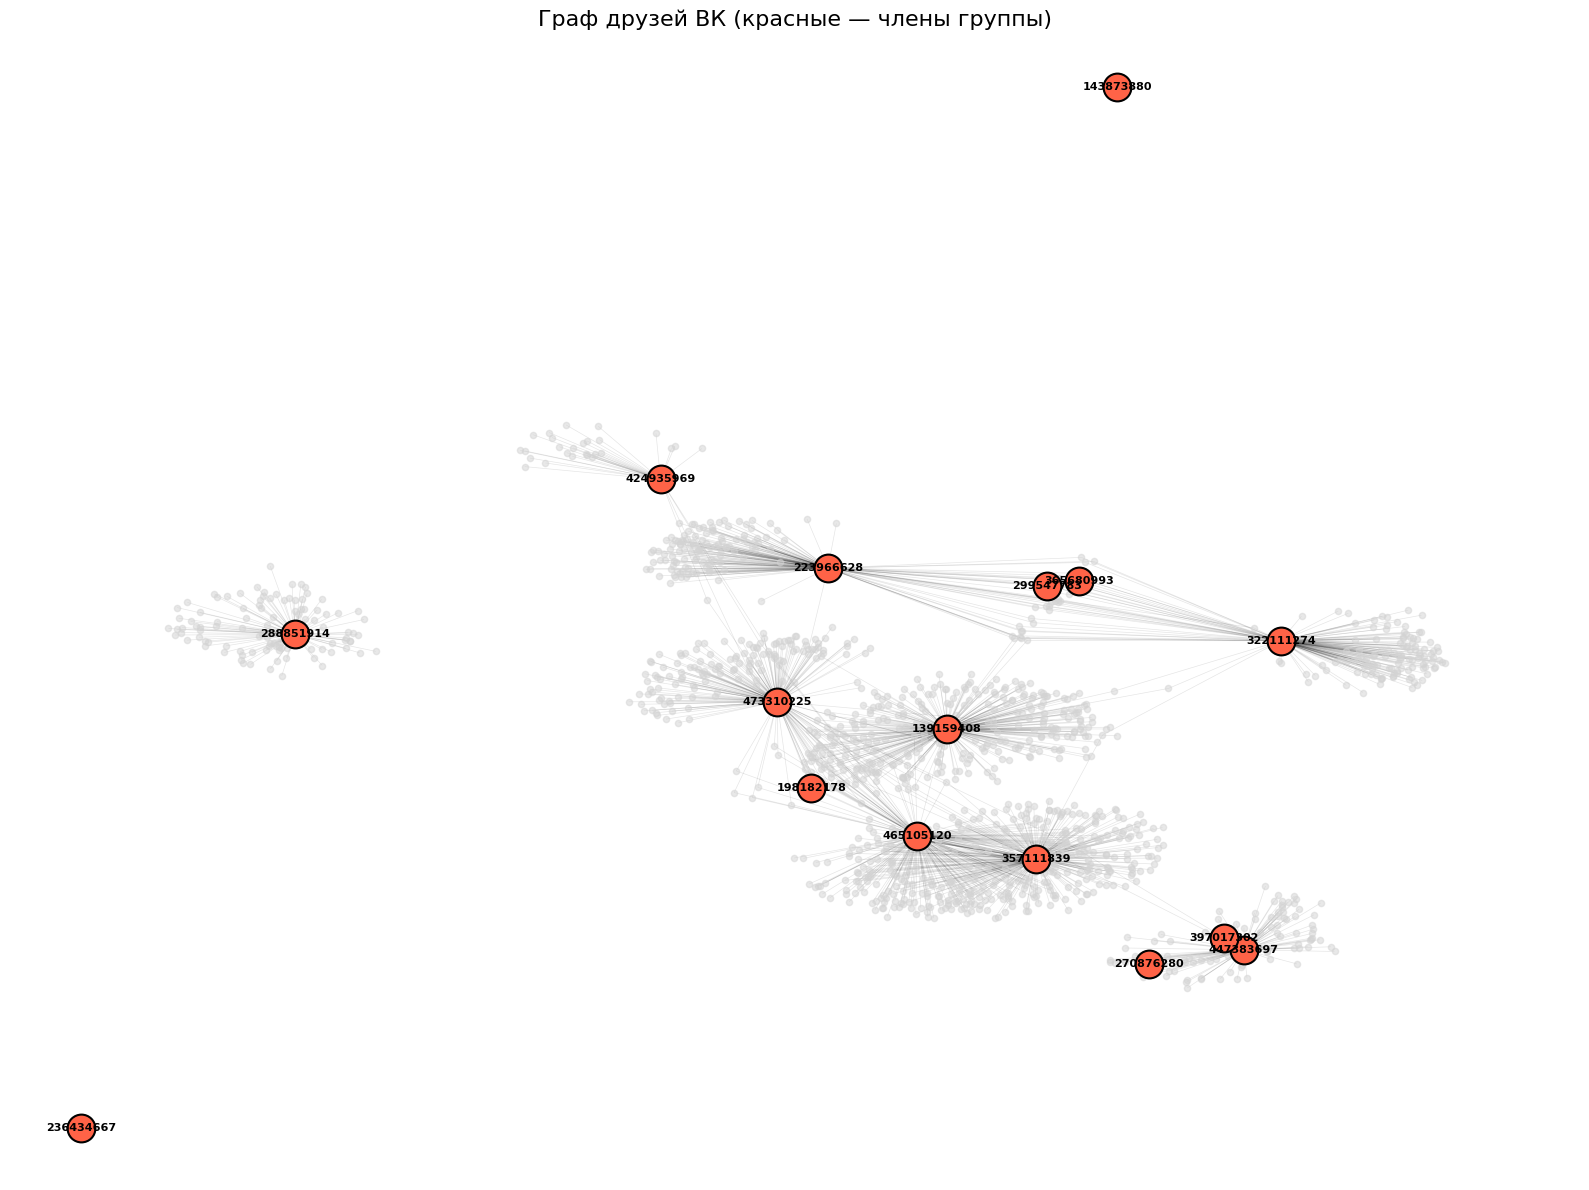

Граф сохранен в vk_graph.png


In [21]:
# import matplotlib.pyplot as plt
# import networkx as nx

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, k=0.3, iterations=50, seed=42)

members_set = set(group_members)
member_nodes = [n for n in G.nodes() if n in members_set]
other_nodes = [n for n in G.nodes() if n not in members_set]

nx.draw_networkx_edges(G, pos, alpha=0.1, width=0.5)
nx.draw_networkx_nodes(G, pos, nodelist=other_nodes, node_size=20, node_color='lightgray', alpha=0.5)
nx.draw_networkx_nodes(G, pos, nodelist=member_nodes, node_size=400, node_color='tomato', edgecolors='black', linewidths=1.5)

labels = {n: str(n) for n in member_nodes}
nx.draw_networkx_labels(G, pos, labels, font_size=8, font_weight='bold')

plt.title("Граф друзей ВК (красные — члены группы)", fontsize=16)
plt.axis('off')
plt.tight_layout()
plt.savefig("vk_graph.png", dpi=150, bbox_inches='tight')
plt.show()

print("Граф сохранен в vk_graph.png")